In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

In [2]:
print(os.getcwd())

C:\Users\Cloud Nine\Documents\Shalini\stats and probability


In [3]:
df = pd.read_csv(r"C:\Users\Cloud Nine\Documents\Shalini\stats and probability\StudentsPerformance.csv")

In [4]:
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB


In [6]:
df['writing score'].mean()

np.float64(68.054)

In [7]:
df['writing score'].median()

69.0

In [8]:
df['writing score'].mode()

0    74
Name: writing score, dtype: int64

In [9]:
df['writing score'].sum()/df['writing score'].count()

np.float64(68.054)

In [10]:
sorteddf = df['writing score'].sort_values()

In [11]:
sorteddf

59      10
596     15
327     19
76      22
980     23
      ... 
970    100
106    100
957    100
916    100
114    100
Name: writing score, Length: 1000, dtype: int64

In [12]:
sorteddf = df['writing score'].sort_values().reset_index(drop=True)

n = sorteddf.count()

if n % 2 == 1:
    median = sorteddf[n // 2]
else:
    middle1 = sorteddf[n // 2 - 1]
    middle2 = sorteddf[n // 2]
    median = (middle1 + middle2) / 2

print("Median:", median)

Median: 69.0


In [13]:
modescores = df['writing score']
freq = {}

for score in modescores:
    if score in freq:
        freq[score]+=1
    else:
        freq[score] = 1

In [14]:
freq

{74: 35,
 88: 11,
 93: 8,
 44: 8,
 75: 22,
 78: 25,
 92: 9,
 39: 2,
 67: 25,
 50: 10,
 52: 20,
 43: 12,
 73: 28,
 70: 33,
 58: 18,
 86: 12,
 28: 1,
 46: 10,
 61: 21,
 63: 15,
 53: 17,
 80: 27,
 72: 25,
 55: 14,
 65: 22,
 38: 6,
 82: 24,
 79: 19,
 83: 13,
 59: 13,
 57: 19,
 54: 25,
 68: 31,
 66: 24,
 62: 27,
 76: 25,
 48: 8,
 42: 7,
 87: 11,
 49: 9,
 10: 1,
 34: 3,
 71: 18,
 37: 2,
 56: 14,
 41: 8,
 22: 1,
 81: 20,
 45: 7,
 36: 4,
 89: 9,
 47: 10,
 90: 10,
 100: 14,
 64: 22,
 98: 2,
 51: 17,
 40: 3,
 84: 16,
 69: 23,
 33: 2,
 60: 20,
 85: 14,
 91: 11,
 77: 24,
 27: 3,
 94: 6,
 95: 8,
 19: 1,
 35: 1,
 32: 2,
 96: 4,
 97: 2,
 99: 4,
 15: 1,
 30: 1,
 23: 1}

In [15]:
mode = max(freq, key=freq.get)

print("Mode:", mode)

Mode: 74


In [16]:
writingScore = df['writing score']

In [17]:
writingScore.var()

230.90799199199168

In [18]:
writingScore.std()

15.195657010869642

In [19]:
Q1 = writingScore.quantile(0.25)
Q2 = writingScore.quantile(0.50)
Q3 = writingScore.quantile(0.75)

In [20]:
IQR = Q3 - Q1
IQR

np.float64(21.25)

In [21]:
lb = Q1 - (1.5 * IQR)
ub = Q3 + (1.5 * IQR)

In [22]:
lb

np.float64(25.875)

In [23]:
ub

np.float64(110.875)

In [24]:
outliers = df[(writingScore < lb) |(writingScore > ub)]

In [25]:
outliers

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
59,female,group C,some high school,free/reduced,none,0,17,10
76,male,group E,some high school,standard,none,30,26,22
327,male,group A,some college,free/reduced,none,28,23,19
596,male,group B,high school,free/reduced,none,30,24,15
980,female,group B,high school,free/reduced,none,8,24,23


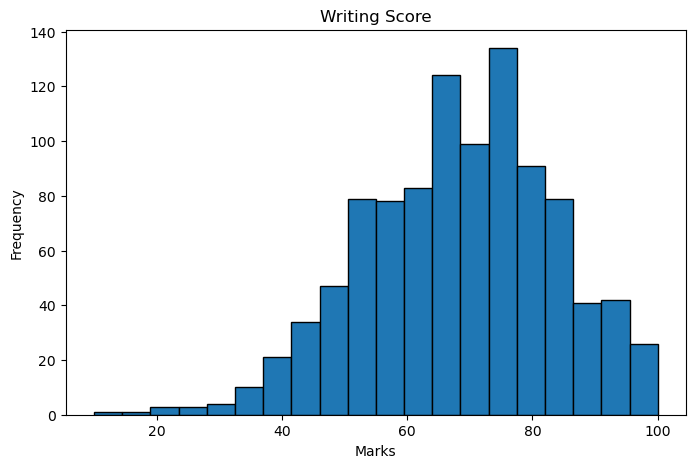

In [26]:
plt.figure(figsize=(8,5))

plt.hist(writingScore, bins=20, edgecolor="black")


plt.title("Writing Score")
plt.xlabel("Marks")
plt.ylabel("Frequency")
plt.show()

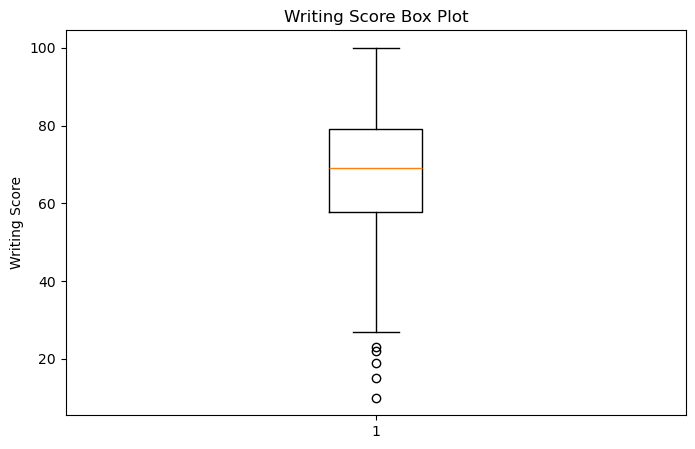

In [27]:
plt.figure(figsize=(8,5))

plt.boxplot(writingScore)

plt.title("Writing Score Box Plot")
plt.ylabel("Writing Score")

plt.show()

#### What is the probability of randomly selecting a female student?

In [28]:
genders = df['gender']

f_count = 0

for gender in genders:
    if gender == 'female':
        f_count +=1

prob = f_count/len(genders)

print(prob*100)

51.800000000000004


#### Probability of selecting a student who has free/reduced lunch?

In [29]:
freeReducedCount = 0

for lunch in df['lunch']:
    if lunch == 'free/reduced':
        freeReducedCount += 1

prob = freeReducedCount/len(df['lunch'])

print(prob*100)

35.5


#### Probability of selecting a student with math score ≥ 30?

In [30]:
count = 0

for score in df['math score']:
    if score >= 30:
        count += 1

prob = score/len(df['math score'])

print(prob*100)


7.7


#### What is the probability that a student is female GIVEN that they have free/reduced lunch?

In [31]:
female_free = 0
free_reduced = 0

for i in range(len(df)):
    if df.loc[i,"lunch"] == 'free/reduced':
        free_reduced += 1
        
        if df.loc[i,"gender"] == 'female':
            female_free += 1
            
prob = female_free/free_reduced

print("Female & Free/Reduced:", female_free)
print("Free/Reduced:", free_reduced)
print("P(Female | Free/Reduced):", prob*100)

Female & Free/Reduced: 189
Free/Reduced: 355
P(Female | Free/Reduced): 53.239436619718305


#### What is the probability of a male student GIVEN that their lunch is free/reduced?

In [32]:
male_free = 0
free_reduced = 0

for i in range(len(df)):
    if df.loc[i,'lunch'] == 'free/reduced':
        free_reduced += 1
        if df.loc[i,'gender'] == 'male':
            male_free += 1
prob = male_free/free_reduced

print(prob*100)
        

46.76056338028169


#### if X = Math score of a randomly selected student, then What values can X take?"

In [33]:
x_values = []

for score in df['math score']:
    if score not in x_values:
        x_values.append(score)

x_values.sort()
print(x_values)

[0, 8, 18, 19, 22, 23, 24, 26, 27, 28, 29, 30, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100]


In [34]:
x_values = df["math score"].unique()  # get possible values
x_values.sort()                       # sort them
print(x_values)                       # display

[  0   8  18  19  22  23  24  26  27  28  29  30  32  33  34  35  36  37
  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53  54  55
  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71  72  73
  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89  90  91
  92  93  94  95  96  97  98  99 100]


#### What is P(X ≥ 28)

In [35]:
count = 0
for score in df['writing score']:
    if score >= 28:
        count += 1
prob = count/len(df['writing score'])
print(prob*100)

99.2


#### Probability Distribution of math score

In [36]:
#Get the possible values

x_values = df["math score"].unique()
x_values.sort()

print(x_values)

[  0   8  18  19  22  23  24  26  27  28  29  30  32  33  34  35  36  37
  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53  54  55
  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71  72  73
  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89  90  91
  92  93  94  95  96  97  98  99 100]


In [37]:
#Calculate frequency manually

frequency = {}

for score in df["math score"]:
    if score in frequency:
        frequency[score] += 1
    else:
        frequency[score] = 1

print(frequency)

{72: 18, 69: 32, 90: 8, 47: 11, 76: 21, 71: 26, 88: 15, 40: 10, 64: 20, 38: 3, 58: 25, 65: 36, 78: 14, 50: 15, 18: 1, 46: 11, 54: 18, 66: 24, 44: 9, 74: 25, 73: 27, 67: 26, 70: 18, 62: 35, 63: 26, 56: 9, 97: 6, 81: 22, 75: 21, 57: 18, 55: 18, 53: 24, 59: 32, 82: 18, 77: 24, 33: 1, 52: 18, 0: 1, 79: 22, 39: 4, 45: 9, 60: 16, 61: 27, 41: 6, 49: 17, 30: 2, 80: 17, 42: 6, 27: 2, 43: 5, 68: 26, 85: 14, 98: 3, 87: 16, 51: 11, 99: 3, 84: 11, 91: 9, 83: 8, 89: 6, 22: 1, 100: 7, 96: 3, 94: 7, 48: 11, 35: 5, 34: 2, 86: 8, 92: 6, 37: 4, 28: 1, 24: 1, 26: 1, 95: 2, 36: 2, 29: 3, 32: 3, 93: 4, 19: 1, 23: 1, 8: 1}


In [38]:
#Calculate probability
total = len(df)

probability = {}

for score, count in frequency.items():
    probability[score] = count / total

print(probability)

{72: 0.018, 69: 0.032, 90: 0.008, 47: 0.011, 76: 0.021, 71: 0.026, 88: 0.015, 40: 0.01, 64: 0.02, 38: 0.003, 58: 0.025, 65: 0.036, 78: 0.014, 50: 0.015, 18: 0.001, 46: 0.011, 54: 0.018, 66: 0.024, 44: 0.009, 74: 0.025, 73: 0.027, 67: 0.026, 70: 0.018, 62: 0.035, 63: 0.026, 56: 0.009, 97: 0.006, 81: 0.022, 75: 0.021, 57: 0.018, 55: 0.018, 53: 0.024, 59: 0.032, 82: 0.018, 77: 0.024, 33: 0.001, 52: 0.018, 0: 0.001, 79: 0.022, 39: 0.004, 45: 0.009, 60: 0.016, 61: 0.027, 41: 0.006, 49: 0.017, 30: 0.002, 80: 0.017, 42: 0.006, 27: 0.002, 43: 0.005, 68: 0.026, 85: 0.014, 98: 0.003, 87: 0.016, 51: 0.011, 99: 0.003, 84: 0.011, 91: 0.009, 83: 0.008, 89: 0.006, 22: 0.001, 100: 0.007, 96: 0.003, 94: 0.007, 48: 0.011, 35: 0.005, 34: 0.002, 86: 0.008, 92: 0.006, 37: 0.004, 28: 0.001, 24: 0.001, 26: 0.001, 95: 0.002, 36: 0.002, 29: 0.003, 32: 0.003, 93: 0.004, 19: 0.001, 23: 0.001, 8: 0.001}


In [39]:
#Put Everything in Dataframe
distribution = pd.DataFrame({
    "X": frequency.keys(),
    "Frequency": frequency.values(),
    "Probability": probability.values()
})

distribution = distribution.sort_values("X")

print(distribution)

      X  Frequency  Probability
37    0          1        0.001
80    8          1        0.001
14   18          1        0.001
78   19          1        0.001
60   22          1        0.001
..  ...        ...          ...
62   96          3        0.003
26   97          6        0.006
52   98          3        0.003
55   99          3        0.003
61  100          7        0.007

[81 rows x 3 columns]


In [40]:
#Check proabilities add upto 1
total_probability = 0

for p in probability.values():
    total_probability += p

print(total_probability)

1.0000000000000007


In [41]:
x_writingScore = sorted(df['writing score'].unique().tolist())
print(x_writingScore)

f = {}
for score in df['writing score']:
    if score in f:
        f[score] += 1
    else:
        f[score] = 1
print(f)
total = len(df)
prob = {}
for score, count in f.items():
    prob[score] = count / total
print(prob)
prob_dist = pd.DataFrame(
    {
        'X' : f.keys(),
        'Frequency' : f.values(),
        'Probability' : prob.values()
    }
)
prob_dist = prob_dist.sort_values('X')
print(prob_dist)
total_prob = 0
for p in prob_dist['Probability']:
    total_prob += p
print(total_prob)

[10, 15, 19, 22, 23, 27, 28, 30, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100]
{74: 35, 88: 11, 93: 8, 44: 8, 75: 22, 78: 25, 92: 9, 39: 2, 67: 25, 50: 10, 52: 20, 43: 12, 73: 28, 70: 33, 58: 18, 86: 12, 28: 1, 46: 10, 61: 21, 63: 15, 53: 17, 80: 27, 72: 25, 55: 14, 65: 22, 38: 6, 82: 24, 79: 19, 83: 13, 59: 13, 57: 19, 54: 25, 68: 31, 66: 24, 62: 27, 76: 25, 48: 8, 42: 7, 87: 11, 49: 9, 10: 1, 34: 3, 71: 18, 37: 2, 56: 14, 41: 8, 22: 1, 81: 20, 45: 7, 36: 4, 89: 9, 47: 10, 90: 10, 100: 14, 64: 22, 98: 2, 51: 17, 40: 3, 84: 16, 69: 23, 33: 2, 60: 20, 85: 14, 91: 11, 77: 24, 27: 3, 94: 6, 95: 8, 19: 1, 35: 1, 32: 2, 96: 4, 97: 2, 99: 4, 15: 1, 30: 1, 23: 1}
{74: 0.035, 88: 0.011, 93: 0.008, 44: 0.008, 75: 0.022, 78: 0.025, 92: 0.009, 39: 0.002, 67: 0.025, 50: 

- Math Score (X)
      ↓
- Count each score
      ↓
- Frequency
      ↓
- Frequency / Total
      ↓
- P(X = x)

##### Pandas Functions & Methods Used in Probability Distribution

| Function / Method | Definition | Example | Return Value |
|---|---|---|---|
| `.value_counts()` | Counts how many times each unique value occurs in a column. | `df["math score"].value_counts()` | A Pandas Series containing each unique value and its frequency. |
| `.sort()` | Sorts the existing list in place. Modifies the original list. | `x_values.sort()` | `None` |
| `sorted()` | Creates and returns a new sorted list without modifying the original. | `sorted(x_values)` | A new sorted list. |
| `.sort_values()` | Sorts a Pandas Series or DataFrame based on its values. | `df.sort_values("math score")` | A new sorted DataFrame by default. |
| `.sort_index()` | Sorts a Pandas Series or DataFrame based on its index labels. | `distribution.sort_index()` | A new sorted Series or DataFrame by default. |
| `len()` | Returns the number of items in an object, such as the number of rows in a DataFrame. | `len(df)` | An integer, e.g., `1000`. |
| `pd.DataFrame()` | Creates a new Pandas DataFrame from dictionaries, lists, Series, etc. | `pd.DataFrame({"Score": [70, 80]})` | A Pandas DataFrame object. |
| `normalize=True` | Converts frequency counts into proportions instead of raw counts. | `df["math score"].value_counts(normalize=True)` | A Pandas Series of proportions between 0 and 1. |
| `.sum()` | Adds all values together. | `probability.sum()` | A single numeric value, e.g., `1.0`. |
| `.idxmax()` | Returns the index label corresponding to the maximum value. | `distribution.idxmax()` | The index label of the maximum value, e.g., `85`. |
| `max()` with `key=` | Finds the item with the maximum value according to a specified function or rule. | `max(freq, key=freq.get)` | The key associated with the maximum value, e.g., `85`. |
| `norm` | Creates a normal distribution object using a specified mean (`loc`) and standard deviation (`scale`). | `norm(loc=70, scale=10)` | A frozen normal distribution object that can calculate probabilities and densities using methods such as `.cdf()` and `.pdf()`. |
| `cumsum()` | Calculates the cumulative sum by adding each value to the sum of all preceding values. | `pmf.cumsum()` | A Series or array of cumulative sums, depending on the input type. |
| `norm.cdf()` | Calculates the cumulative probability of a value in a normal distribution, i.e., the probability that a value is less than or equal to a specified value. | `norm.cdf(80, loc=70, scale=10)` | A probability between `0` and `1`, e.g., `0.8413` (84.13%). |
| `norm.pdf()` | Calculates the probability density at a specified value in a normal distribution. | `norm.pdf(70, loc=70, scale=10)` | A probability density value, e.g., `0.0399`. It is not the probability of obtaining exactly 70. |

##### Example

```python
frequency = df["math score"].value_counts().sort_index()

probability = frequency / len(df)

distribution = pd.DataFrame({
    "Frequency": frequency,
    "Probability": probability
})

In [42]:
# Frequency of each math score
frequency = df["math score"].value_counts().sort_index()

# Probability of each score
probability = frequency / len(df)

# Create probability distribution
distribution = pd.DataFrame({
    "Frequency": frequency,
    "Probability": probability
})

print(distribution)

most_common_score = distribution["Frequency"].idxmax()

print("Most probable score:", most_common_score)

expected_value = (
    distribution.index * distribution["Probability"]
).sum()

print("Expected Math Score:", expected_value)

            Frequency  Probability
math score                        
0                   1        0.001
8                   1        0.001
18                  1        0.001
19                  1        0.001
22                  1        0.001
...               ...          ...
96                  3        0.003
97                  6        0.006
98                  3        0.003
99                  3        0.003
100                 7        0.007

[81 rows x 2 columns]
Most probable score: 65
Expected Math Score: 66.08900000000001


In [43]:
distribution = (
    df["math score"]
    .value_counts(normalize=True)
    .sort_index()
)

print(distribution)
print(distribution.sum())

math score
0      0.001
8      0.001
18     0.001
19     0.001
22     0.001
       ...  
96     0.003
97     0.006
98     0.003
99     0.003
100    0.007
Name: proportion, Length: 81, dtype: float64
1.0


#### What is P(X >= 80)?

In [44]:
distribution.loc[80:].sum()*100

np.float64(19.3)

In [45]:
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


### Round 1 - Basic Probabiity

In [46]:
#X = Reading score of a randomly selected student

possible_reading_score = []
for score in df['reading score']:
    if score not in possible_reading_score:
        possible_reading_score.append(score)
possible_reading_score.sort()
print(possible_reading_score)

#python functions
reading_score = sorted(df['reading score'].unique().tolist())

[17, 23, 24, 26, 28, 29, 31, 32, 34, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 99, 100]


In [47]:
#What is the probability that a randomly selected student has a reading score of 70 or above?
count = 0
for score in df['reading score']:
    if score >= 70:
        count += 1
P_70_or_above = count/len(df)
print("Reading Score >= 70 : ",count)
print("Total Reading : ",len(df['reading score']))
print("Probability of Reading Score >= 70 - ",P_70_or_above*100)

Reading Score >= 70 :  513
Total Reading :  1000
Probability of Reading Score >= 70 -  51.300000000000004


In [48]:
#What is the probability that a student has a reading score below 50?
count = 0
for score in df['reading score']:
    if score < 50:
        count += 1
P_less_than_50 = count/len(df['reading score'])
print("Reading Score < 50 : ",count)
print("Total Reading : ",len(df['reading score']))
print("Probability of Reading Score < 50 : ",P_less_than_50*100)

Reading Score < 50 :  90
Total Reading :  1000
Probability of Reading Score < 50 :  9.0


In [49]:
#What is the probability that a randomly selected student is female?
count = 0
for gender in df['gender']:
    if gender == 'female':
        count += 1
P_female = count/len(df)
print('Total Female : ', count)
print('Total People : ', len(df))
print('Probability of Selecting a female is', P_female*100)

Total Female :  518
Total People :  1000
Probability of Selecting a female is 51.800000000000004


In [50]:
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [51]:
count = 0
for lunch in df['lunch']:
    if lunch == 'standard':
        count += 1
P_standard = count / len(df)
print('Standard Lunch : ', count)
print('Total : ', len(df))
print('Probability of having a standard lunch is', P_standard*100)

Standard Lunch :  645
Total :  1000
Probability of having a standard lunch is 64.5


In [52]:
#What is the probability that a student completed the test preparation course?
count = 0
for test_preparation_course in df['test preparation course']:
    if test_preparation_course == 'completed':
        count += 1
P_completed = count / len(df)
print('Completed : ', count)
print('Total : ', len(df))
print('Probability of completing the test preparation is', P_completed*100)

Completed :  358
Total :  1000
Probability of completing the test preparation is 35.8


### Round 2 - Conditional Probability

In [53]:
#What is the probability that a student is female given that their reading score is 70 or above?
count_70_or_above = 0
count_female = 0
for index, row in df.iterrows():
    if row['reading score'] >= 70:
        count_70_or_above += 1
        
        if row['gender'] == 'female':
                count_female += 1
prob = count_female/count_70_or_above
print('Female with reading score >= 70: ', count_female)
print('Reading Score >= 70 : ', count_70_or_above)
print('Probability that a student is female given that their reading score is 70 or above', prob*100)

Female with reading score >= 70:  318
Reading Score >= 70 :  513
Probability that a student is female given that their reading score is 70 or above 61.98830409356725


In [54]:
count_70_or_above = 0
count_female = 0
for i in range(len(df)):
    if df.loc[i,'reading score']>= 70:
        count_70_or_above += 1
        if df.loc[i,'gender'] == 'female':
            count_female += 1
prob = count_female/count_70_or_above

print(prob*100)
        

61.98830409356725


In [55]:
eligible = df[df['reading score'] >= 70]
prob = (eligible['gender'] == 'female').mean()
prob*100

np.float64(61.98830409356725)

In [56]:
#What is the probability that a student has standard lunch given that their reading score is 70 or above?
eligible = df[df['reading score'] >= 70]
prob = (eligible['lunch'] == 'standard').mean()
print(prob)

rs_cnt = 0
standard_cnt = 0
for index,row in df.iterrows():
    if row['reading score'] >= 70:
        rs_cnt += 1
        if row['lunch'] == 'standard':
            standard_cnt += 1
prob = standard_cnt/rs_cnt
print(prob)
            
        

0.732943469785575
0.732943469785575


In [57]:
#What is the probability that a student completed the test preparation course given that their reading score is below 50?
eligible = df[df['reading score'] < 50]
print((eligible['test preparation course'] == 'completed').mean())

rs_cnt = 0
completed_cnt = 0
for i in range(len(df)):
    if df.loc[i,'reading score'] < 50:
        rs_cnt += 1
        if df.loc[i, 'test preparation course'] == 'completed':
            completed_cnt += 1
print(completed_cnt / rs_cnt)
    

0.17777777777777778
0.17777777777777778


### Round 3 — Random Variable
Define:
X = Reading score of a randomly selected student



In [58]:
#What is P(X=50)
print((df['reading score'] == 50).mean())

count = 0
for score in df['reading score']:
    if score == 50:
        count += 1
prob = count/len(df)
print(prob)

0.007
0.007


In [59]:
#What is P(60<=X<=80)
print(((df['reading score'] >= 60) & (df['reading score'] <= 80)).mean()*100)
count = 0
for index,row in df.iterrows():
    if (row['reading score'] >= 60) & (row['reading score'] <=80):
        count += 1
prob = count/len(df)
print(prob*100)

51.1
51.1


In [60]:
#What is the most probable reading score?
freq = {}
for score in df['reading score']:
    if score in freq:
        freq[score] += 1
    else:
        freq[score] = 1
print(freq)
most_frequent = max(freq, key=freq.get)

print(most_frequent)

df['reading score'].value_counts().idxmax()

{72: 34, 90: 17, 95: 8, 57: 17, 78: 27, 83: 14, 43: 9, 64: 32, 60: 21, 54: 18, 52: 16, 81: 25, 53: 13, 75: 26, 89: 12, 32: 1, 42: 7, 58: 28, 69: 15, 73: 30, 71: 20, 74: 33, 70: 26, 65: 19, 87: 13, 56: 16, 61: 24, 84: 26, 55: 16, 44: 4, 41: 6, 85: 18, 59: 17, 17: 1, 39: 6, 80: 14, 37: 3, 63: 20, 51: 16, 49: 10, 26: 1, 68: 23, 45: 7, 47: 4, 86: 19, 34: 4, 79: 19, 66: 27, 67: 30, 91: 6, 100: 17, 76: 25, 77: 24, 82: 20, 92: 10, 93: 6, 62: 22, 88: 9, 50: 7, 28: 1, 48: 10, 46: 6, 23: 1, 38: 2, 94: 3, 97: 5, 99: 3, 31: 2, 96: 4, 24: 2, 29: 2, 40: 1}
72


np.int64(72)

In [61]:
#Create a probability distribution for reading score.

In [62]:
prob = {}
for value,frequency in freq.items():
    prob[value] = frequency/sum(freq.values())
prob

{72: 0.034,
 90: 0.017,
 95: 0.008,
 57: 0.017,
 78: 0.027,
 83: 0.014,
 43: 0.009,
 64: 0.032,
 60: 0.021,
 54: 0.018,
 52: 0.016,
 81: 0.025,
 53: 0.013,
 75: 0.026,
 89: 0.012,
 32: 0.001,
 42: 0.007,
 58: 0.028,
 69: 0.015,
 73: 0.03,
 71: 0.02,
 74: 0.033,
 70: 0.026,
 65: 0.019,
 87: 0.013,
 56: 0.016,
 61: 0.024,
 84: 0.026,
 55: 0.016,
 44: 0.004,
 41: 0.006,
 85: 0.018,
 59: 0.017,
 17: 0.001,
 39: 0.006,
 80: 0.014,
 37: 0.003,
 63: 0.02,
 51: 0.016,
 49: 0.01,
 26: 0.001,
 68: 0.023,
 45: 0.007,
 47: 0.004,
 86: 0.019,
 34: 0.004,
 79: 0.019,
 66: 0.027,
 67: 0.03,
 91: 0.006,
 100: 0.017,
 76: 0.025,
 77: 0.024,
 82: 0.02,
 92: 0.01,
 93: 0.006,
 62: 0.022,
 88: 0.009,
 50: 0.007,
 28: 0.001,
 48: 0.01,
 46: 0.006,
 23: 0.001,
 38: 0.002,
 94: 0.003,
 97: 0.005,
 99: 0.003,
 31: 0.002,
 96: 0.004,
 24: 0.002,
 29: 0.002,
 40: 0.001}

In [63]:
dist = pd.DataFrame(
    {
        'Reading Score' : freq.keys(),
         'Frequency' : freq.values(),
        'Probability' : prob.values()
    }
)
dist

,Reading Score,Frequency,Probability
0,72,34,0.034
1,90,17,0.017
2,95,8,0.008
3,57,17,0.017
4,78,27,0.027
...,...,...,...
67,31,2,0.002
68,96,4,0.004
69,24,2,0.002
70,29,2,0.002


In [64]:
dist = dist.sort_values('Reading Score')

In [65]:
dist

,Reading Score,Frequency,Probability
33,17,1,0.001
62,23,1,0.001
69,24,2,0.002
40,26,1,0.001
59,28,1,0.001
...,...,...,...
2,95,8,0.008
68,96,4,0.004
65,97,5,0.005
66,99,3,0.003


In [66]:
total = 0
for p in dist['Probability']:
    total += p
total

1.0000000000000007

In [67]:
dist[dist['Reading Score'] == 80]['Probability']

35    0.014
Name: Probability, dtype: float64

In [68]:
dist.loc[dist['Reading Score'] >= 80, 'Probability'].sum()

np.float64(0.24900000000000005)

In [69]:
dist[dist['Probability'] == dist['Probability'].max()]

,Reading Score,Frequency,Probability
0,72,34,0.034


In [70]:
dist.loc[dist['Probability'].idxmax(), 'Reading Score']

np.int64(72)

In [71]:
dist

,Reading Score,Frequency,Probability
33,17,1,0.001
62,23,1,0.001
69,24,2,0.002
40,26,1,0.001
59,28,1,0.001
...,...,...,...
2,95,8,0.008
68,96,4,0.004
65,97,5,0.005
66,99,3,0.003


In [72]:
(dist['Reading Score'] * dist['Probability']).sum()

np.float64(69.16900000000001)

In [73]:
dist['Reading Score'].mean()

np.float64(62.916666666666664)

In [74]:
distribution = df["reading score"].value_counts(normalize=True).sort_index()
expected_value = (distribution.index * distribution).sum()

print(expected_value)

69.16900000000001


In [75]:
mean = df["reading score"].mean()

print(mean)

69.169


In [76]:
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [77]:
math = df['math score']

In [78]:
math.mean()

np.float64(66.089)

In [79]:
math.median()

66.0

In [80]:
math.mode()

0    65
Name: math score, dtype: int64

In [81]:
count = 0
for score in math:
    if score < 35:
        count += 1
print("Total number of students who has failed :",count)
print("Total number of students :",len(math))
prob_of_fail = count/len(math)
print("Probability of Students who has failed : ",prob_of_fail*100)

Total number of students who has failed : 22
Total number of students : 1000
Probability of Students who has failed :  2.1999999999999997


In [82]:
df['parental level of education'].unique()

array(["bachelor's degree", 'some college', "master's degree",
       "associate's degree", 'high school', 'some high school'],
      dtype=object)

In [83]:
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [84]:
df['parental level of education'].value_counts()

parental level of education
some college          226
associate's degree    222
high school           196
some high school      179
bachelor's degree     118
master's degree        59
Name: count, dtype: int64

In [85]:
#probability of students failed given the parental level of education is high school
total_fail = 0
failed_given_high_school = 0
highschool_count = 0

for score in df['math score']:
    if score < 35:
        total_fail += 1
prob_of_fail = total_fail/len(df['math score'])

for index,row in df.iterrows():
    if row['parental level of education'] in {'high school','some high school'}:
        highschool_count += 1
        if row['math score'] < 35:
            failed_given_high_school += 1 
            
print("Total number of students who has failed :",total_fail)
print("Total number of students failed given that their parental level of education is high school:", failed_given_high_school)
print("Total number of students with parental level of education is high school :", highschool_count)
print("Probability of Students who has failed : ",prob_of_fail*100)
print("Probability of Students failed given that their parental level of education is high school",failed_given_high_school/highschool_count*100)
print("Probability of failed students with parental level of education high school given failed students",failed_given_high_school/total_fail*100)

Total number of students who has failed : 22
Total number of students failed given that their parental level of education is high school: 16
Total number of students with parental level of education is high school : 375
Probability of Students who has failed :  2.1999999999999997
Probability of Students failed given that their parental level of education is high school 4.266666666666667
Probability of failed students with parental level of education high school given failed students 72.72727272727273


In [86]:
#probability of students passed given the parental level of education is high school
count = 0
for score in df['math score']:
    if score >= 35:
        count += 1

passed_given_high_school = 0
highschool_count = 0
for index,row in df.iterrows():
    if row['parental level of education'] in {'high school','some high school'}:
        highschool_count += 1
        if row['math score'] >= 35:
            passed_given_high_school += 1 
prob_of_pass = count/len(df['math score'])
print("Total number of students who has passed :",count)
print("Total number of students passed given that their parental level of education is high school:", passed_given_high_school)
print("Total number of students with parental level of education is high school :", highschool_count)
print("Probability of Students who has passed : ",prob_of_pass*100)
print("Probability of Students passed given that their parental level of education is high school P(Pass | High School)",passed_given_high_school/highschool_count*100)
print("Probability of Students passed with parental level of education high school given students passed P(High School Pass | Pass)",passed_given_high_school/count*100)

Total number of students who has passed : 978
Total number of students passed given that their parental level of education is high school: 359
Total number of students with parental level of education is high school : 375
Probability of Students who has passed :  97.8
Probability of Students passed given that their parental level of education is high school P(Pass | High School) 95.73333333333333
Probability of Students passed with parental level of education high school given students passed P(High School Pass | Pass) 36.70756646216769


In [87]:
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [88]:
failed_students = df[df['math score'] < 35]
failed_students = failed_students.reset_index(drop=True)

In [89]:
failed_students['parental level of education'].value_counts(normalize=True)*100

parental level of education
some high school      36.363636
high school           36.363636
some college          18.181818
associate's degree     4.545455
bachelor's degree      4.545455
Name: proportion, dtype: float64

In [90]:
df.groupby('parental level of education')['math score'].mean()

parental level of education
associate's degree    67.882883
bachelor's degree     69.389831
high school           62.137755
master's degree       69.745763
some college          67.128319
some high school      63.497207
Name: math score, dtype: float64

In [91]:
df.groupby('parental level of education')['math score'].std()

parental level of education
associate's degree    15.112093
bachelor's degree     14.943789
high school           14.539651
master's degree       15.153915
some college          14.312897
some high school      15.927989
Name: math score, dtype: float64

In [92]:
df

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75
...,...,...,...,...,...,...,...,...
995,female,group E,master's degree,standard,completed,88,99,95
996,male,group C,high school,free/reduced,none,62,55,55
997,female,group C,high school,free/reduced,completed,59,71,65
998,female,group D,some college,standard,completed,68,78,77


In [93]:
freq = {}
for score in df['math score']:
    if score in freq:
        freq[score] += 1
    else:
        freq[score] = 1
print(freq)

{72: 18, 69: 32, 90: 8, 47: 11, 76: 21, 71: 26, 88: 15, 40: 10, 64: 20, 38: 3, 58: 25, 65: 36, 78: 14, 50: 15, 18: 1, 46: 11, 54: 18, 66: 24, 44: 9, 74: 25, 73: 27, 67: 26, 70: 18, 62: 35, 63: 26, 56: 9, 97: 6, 81: 22, 75: 21, 57: 18, 55: 18, 53: 24, 59: 32, 82: 18, 77: 24, 33: 1, 52: 18, 0: 1, 79: 22, 39: 4, 45: 9, 60: 16, 61: 27, 41: 6, 49: 17, 30: 2, 80: 17, 42: 6, 27: 2, 43: 5, 68: 26, 85: 14, 98: 3, 87: 16, 51: 11, 99: 3, 84: 11, 91: 9, 83: 8, 89: 6, 22: 1, 100: 7, 96: 3, 94: 7, 48: 11, 35: 5, 34: 2, 86: 8, 92: 6, 37: 4, 28: 1, 24: 1, 26: 1, 95: 2, 36: 2, 29: 3, 32: 3, 93: 4, 19: 1, 23: 1, 8: 1}


In [94]:
prob = {}
for key,value in freq.items():
    prob[key] = value/len(df)
prob

{72: 0.018,
 69: 0.032,
 90: 0.008,
 47: 0.011,
 76: 0.021,
 71: 0.026,
 88: 0.015,
 40: 0.01,
 64: 0.02,
 38: 0.003,
 58: 0.025,
 65: 0.036,
 78: 0.014,
 50: 0.015,
 18: 0.001,
 46: 0.011,
 54: 0.018,
 66: 0.024,
 44: 0.009,
 74: 0.025,
 73: 0.027,
 67: 0.026,
 70: 0.018,
 62: 0.035,
 63: 0.026,
 56: 0.009,
 97: 0.006,
 81: 0.022,
 75: 0.021,
 57: 0.018,
 55: 0.018,
 53: 0.024,
 59: 0.032,
 82: 0.018,
 77: 0.024,
 33: 0.001,
 52: 0.018,
 0: 0.001,
 79: 0.022,
 39: 0.004,
 45: 0.009,
 60: 0.016,
 61: 0.027,
 41: 0.006,
 49: 0.017,
 30: 0.002,
 80: 0.017,
 42: 0.006,
 27: 0.002,
 43: 0.005,
 68: 0.026,
 85: 0.014,
 98: 0.003,
 87: 0.016,
 51: 0.011,
 99: 0.003,
 84: 0.011,
 91: 0.009,
 83: 0.008,
 89: 0.006,
 22: 0.001,
 100: 0.007,
 96: 0.003,
 94: 0.007,
 48: 0.011,
 35: 0.005,
 34: 0.002,
 86: 0.008,
 92: 0.006,
 37: 0.004,
 28: 0.001,
 24: 0.001,
 26: 0.001,
 95: 0.002,
 36: 0.002,
 29: 0.003,
 32: 0.003,
 93: 0.004,
 19: 0.001,
 23: 0.001,
 8: 0.001}

In [95]:
prob_dist = pd.DataFrame(
    {
        'value' : freq.keys(),
        'frequency' : freq.values(),
        'prob' : prob.values()
    }
)

In [96]:
prob_dist.sort_values('value').reset_index(drop=True)

,value,frequency,prob
0,0,1,0.001
1,8,1,0.001
2,18,1,0.001
3,19,1,0.001
4,22,1,0.001
...,...,...,...
76,96,3,0.003
77,97,6,0.006
78,98,3,0.003
79,99,3,0.003


In [97]:
prob_dist.sort_index()

,value,frequency,prob
0,72,18,0.018
1,69,32,0.032
2,90,8,0.008
3,47,11,0.011
4,76,21,0.021
...,...,...,...
76,32,3,0.003
77,93,4,0.004
78,19,1,0.001
79,23,1,0.001


In [98]:
 prob_dist[(prob_dist['prob'] > 40/100) & (prob_dist['prob'] < 70/100)]

,value,frequency,prob


In [99]:
 prob_dist[(prob_dist['prob'] <= 80/100) & (prob_dist['prob'] >= 50/100)]

,value,frequency,prob


In [100]:
(prob_dist['value'] * prob_dist['prob']).sum()

np.float64(66.089)

In [101]:
df['math score'].mean()

np.float64(66.089)

In [102]:
prob_dist['prob'].sum()

np.float64(1.0)

Mean: 66.089
Standard deviation: 15.163080096009468


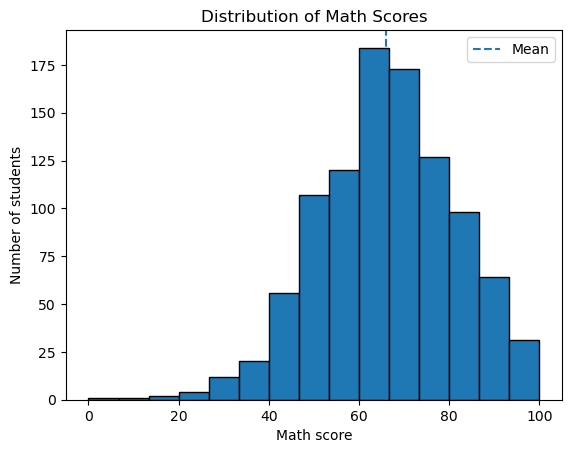

In [103]:
import pandas as pd
import matplotlib.pyplot as plt

scores = df["math score"].dropna()

mean_score = scores.mean()
std_score = scores.std()

print("Mean:", mean_score)
print("Standard deviation:", std_score)

plt.hist(scores, bins=15, edgecolor="black")
plt.axvline(mean_score, linestyle="--",
            label="Mean")
plt.xlabel("Math score")
plt.ylabel("Number of students")
plt.title("Distribution of Math Scores")
plt.legend()
plt.show()

Mean: 66.089
Standard deviation: 15.163080096009468


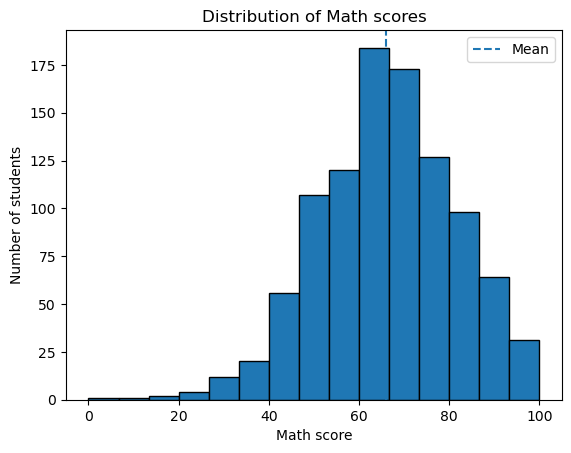

In [104]:
math_scores = df['math score'].dropna()
mean_score = math_scores.mean()
std_score = math_scores.std()
print("Mean:", mean_score)
print("Standard deviation:", std_score)

plt.hist(math_scores, bins = 15,edgecolor = 'black')
plt.axvline(mean_score, linestyle = '--', label = 'Mean')
plt.xlabel('Math score')
plt.ylabel('Number of students')
plt.title('Distribution of Math scores')
plt.legend()
plt.show()

In [105]:
within_1_sd = (
    (math_scores >= mean_score - std_score) &
    (math_scores <= mean_score + std_score)
)
within_2_sd = (
    (math_scores >= mean_score - 2*std_score) & (math_scores <= mean_score + 2*std_score)
)
within_3_sd = (
   ( math_scores >= mean_score - 3*std_score) & (math_scores <= mean_score + 3*std_score)
)
perc_2sd = within_2_sd.mean() * 100
percentage_1_sd = within_1_sd.mean() * 100
percentage_3_sd = within_3_sd.mean() * 100

print("Within 1 standard deviation:", percentage_1_sd, "%")
print("Within 2 standard deviation:", perc_2sd, "%")
print("Within 3 standard deviation:", percentage_3_sd, "%")

Within 1 standard deviation: 69.6 %
Within 2 standard deviation: 95.39999999999999 %
Within 3 standard deviation: 99.6 %


In [106]:
df["math_z_score"] = (math_scores - mean_score) / std_score

print(df[["math score", "math_z_score"]].head())

   math score  math_z_score
0          72      0.389828
1          69      0.191979
2          90      1.576922
3          47     -1.258913
4          76      0.653627


In [107]:
df['math_score_z'] = (math_scores - mean_score)/std_score


In [108]:
df['math_score_z'].head().max()

1.576922356711204

In [109]:
df[df['math_score_z']<0].head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,math_z_score,math_score_z
3,male,group A,associate's degree,free/reduced,none,47,57,44,-1.258913,-1.258913
7,male,group B,some college,free/reduced,none,40,43,39,-1.720561,-1.720561
8,male,group D,high school,free/reduced,completed,64,64,67,-0.137769,-0.137769
9,female,group B,high school,free/reduced,none,38,60,50,-1.852460,-1.852460
10,male,group C,associate's degree,standard,none,58,54,52,-0.533467,-0.533467


In [110]:
from scipy.stats import norm

mean_score = 70
std_score = 10
score = 80

p_below = norm.cdf(score, loc=mean_score, scale=std_score)
p_above = 1 - p_below

print("Probability below 80:", p_below * 100, "%")
print("Probability above 80:", p_above * 100, "%")

Probability below 80: 84.1344746068543 %
Probability above 80: 15.865525393145708 %


In [111]:
from scipy.stats import norm

norm.cdf(70, loc=70, scale=10)

np.float64(0.5)

In [112]:
p_50_or_less = norm.cdf(50,loc=70,scale=10)
p_50_or_less*100

np.float64(2.2750131948179195)

P(60 <= X <= 80)=F(80)-F(60)


In [113]:
norm.cdf(80,loc=70,scale=10) - norm.cdf(60,loc=70,scale=10)

np.float64(0.6826894921370859)

In [114]:
# z score < 90
z = (90 - mean_score) /std_score
print(z)
norm.cdf(90,loc=70,scale=10)*100
rem = 1 - 0.8413
rem

2.0


0.15869999999999995

### Probability Density Curve

Mean: 66.089
Standard Deviation: 15.163080096009468


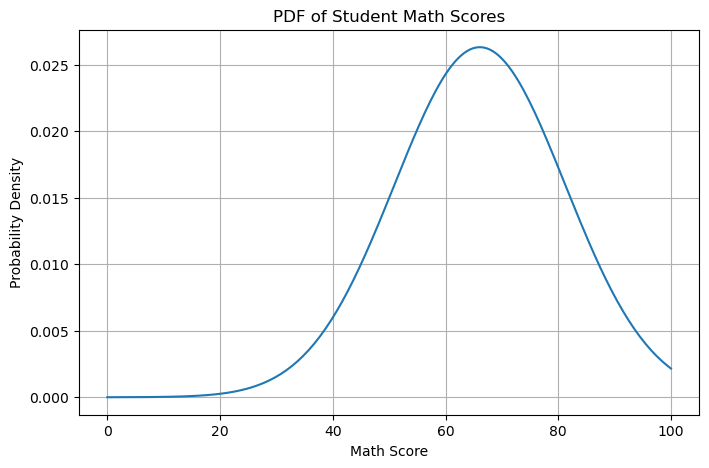

In [115]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# 1. Select math scores and remove missing values
scores = df["math score"].dropna()

# 2. Calculate mean and standard deviation
mean_score = scores.mean()
std_score = scores.std()

print("Mean:", mean_score)
print("Standard Deviation:", std_score)

# 3. Create a normal distribution model normal_dist stores a frozen distribution object: a normal distribution with those parameters fixed. 
#It returns a SciPy distribution object, not a probability or a DataFrame.
#You can then use that object to calculate probabilities and densities without repeatedly specifying the mean and standard deviation.
#ex - normal_dist.cdf(90) - Probability of a score <= 90 normal_dist.pdf(90) - Probability density at score 90
normal_dist = norm(loc=mean_score, scale=std_score)

# 4. Generate x-values between 0 and 100 - Returns numpy array
x_values = np.linspace(0, 100, 200)

# 5. Calculate PDF values 
#pdf() stands for Probability Density Function. - It calculates the normal distribution's probability density at each value in x_values.
#For example -normal_dist.pdf(70) - returns one density value at 70. 
#But because x_values contains 200 numbers, this:returns a NumPy array containing 200 density values, one for each x-value.
pdf_values = normal_dist.pdf(x_values)

# 6. Plot the PDF curve
plt.figure(figsize=(8, 5))
plt.plot(x_values, pdf_values)
plt.title("PDF of Student Math Scores")
plt.xlabel("Math Score")
plt.ylabel("Probability Density")
plt.grid(True)
plt.show()

In [116]:
# Probability that math score is between 60 and 80
probability = normal_dist.cdf(80) - normal_dist.cdf(60)
print("Modelled Probability:", probability * 100)

Modelled Probability: 47.6539025367369


In [117]:
actual_probability = ((scores >= 60) & (scores <= 80)).mean()
print("Actual Probability:", actual_probability * 100)

Actual Probability: 50.1


- Modelled probability (47.65%): Your fitted normal distribution estimates the probability of a score between 60 and 80.
- Actual proportion (50.1%): In your dataset, 50.1% of students actually scored between 60 and 80.
- Why they differ: The normal distribution is an approximation. The actual scores may not follow a perfectly normal distribution.

1. When you have all the data, use actual proportion
Suppose your dataset contains 1,000 students.
- 501 students scored between 60 and 80.
- Actual proportion = \(501/1000 = 50.1\%\)
You know what happened, so there's no need to use a normal distribution to estimate it.
2. But what if you want to know something about students you haven't measured?
Imagine a school has 100,000 students, but you only have scores for 1,000 of them.
You want to estimate the probability that a randomly selected student scores between 60 and 80.
You have two options:
- Actual proportion: Use the 1,000 students' data. It gives 50.1% in your sample, assuming those students are representative.
- Normal model: Use the fitted normal distribution to estimate the probability, which in your example is 47.65%.
Neither method guarantees the correct answer for all 100,000 students. The actual proportion from your sample is also an estimate of the larger population's behaviour.
The normal model is useful when its assumptions are reasonable and it provides a convenient way to calculate probabilities.
3. What if you want a probability for a score you haven't observed?
Suppose you want to estimate the probability of a score falling between 73 and 74.
You could calculate the actual proportion in your dataset. But perhaps only a few students—or none—scored in that narrow interval.
A fitted probability distribution gives you a way to estimate probabilities for ranges like this, even when your observed data is sparse. Whether that estimate is good depends on how well the model represents the real score distribution.
4. So why did your model give a different answer?
Because a normal distribution assumes scores follow a particular smooth, bell-shaped pattern. Real student scores may not follow that pattern exactly.
The model isn't automatically wrong just because it differs from your dataset. However, if the model doesn't fit the data well, its probability estimates may be less reliable.

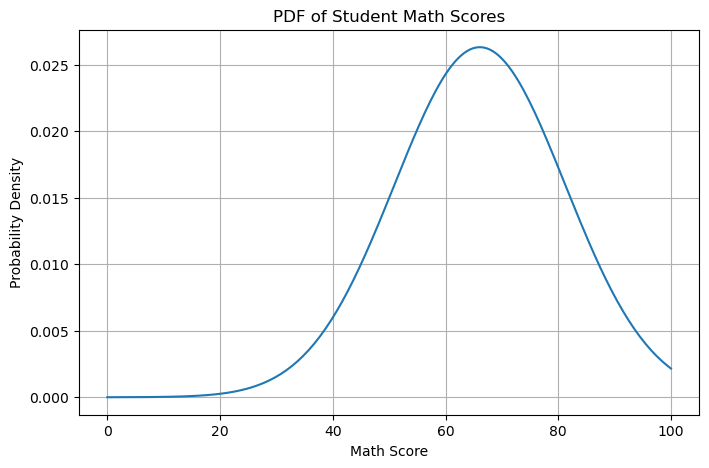

In [118]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

scores = df["math score"].dropna()
mean_score = scores.mean()
std_score = scores.std()
normal_dist = norm(loc=mean_score, scale=std_score)
x_values = np.linspace(0, 100, 200)
pdf_values = normal_dist.pdf(x_values)

# 6. Plot the PDF curve
plt.figure(figsize=(8, 5))
plt.plot(x_values, pdf_values)
plt.title("PDF of Student Math Scores")
plt.xlabel("Math Score")
plt.ylabel("Probability Density")
plt.grid(True)
plt.show()

### Cumulative Probability

In [119]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Get valid math scores
scores = df["math score"].dropna()

# 2. Count the frequency of each score
frequency = scores.value_counts().sort_index()

# 3. Calculate the PMF
pmf = frequency / len(scores)

# 4. Calculate the CDF
cdf = pmf.cumsum()

# 5. Display the CDF table
cdf_table = cdf.reset_index()
cdf_table.columns = ["Math Score", "Cumulative Probability"]

print(cdf_table.head(10))

   Math Score  Cumulative Probability
0           0                   0.001
1           8                   0.002
2          18                   0.003
3          19                   0.004
4          22                   0.005
5          23                   0.006
6          24                   0.007
7          26                   0.008
8          27                   0.010
9          28                   0.011


plt.step(cdf.index, cdf.values, where="post") - Draws a step graph using your CDF data.
- cdf.index — provides the x-axis values, which are your math scores.
- cdf.values — provides the y-axis values, which are the cumulative probabilities corresponding to those scores.
- where="post" — keeps each horizontal step at its current cumulative probability until the next x-value, then changes to the next probability.
Follow the line, one step at a time
1. At score 40, the cumulative probability is 0.10.
2. The line stays horizontal at 0.10 until the next score, 50.
3. At 50, it jumps vertically to 0.30.
4. It stays horizontal at 0.30 until 60, then jumps to 0.60.
5. At 70, it jumps again to 1.00.
That's why it's called a step graph: it looks like a staircase.
- Why use where="post"?
- where="post" means the horizontal line extends to the right of each score until the next score.
For example, the line stays at 0.30 from score 50 up to score 60, then jumps to 0.60.

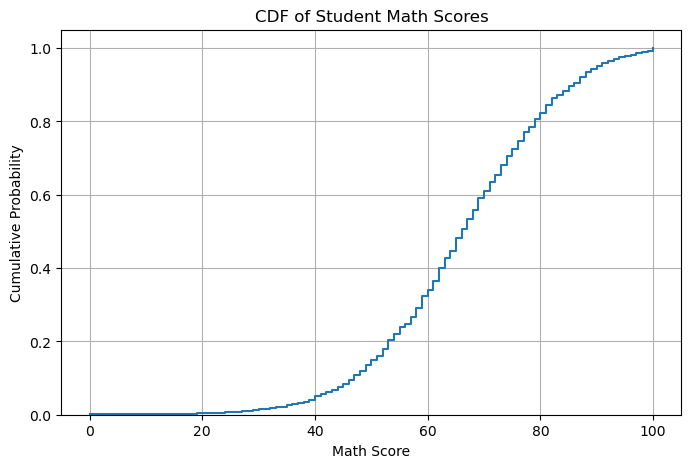

In [123]:
plt.figure(figsize=(8, 5))


plt.step(cdf.index, cdf.values, where="post")

plt.title("CDF of Student Math Scores")
plt.xlabel("Math Score")
plt.ylabel("Cumulative Probability")
plt.ylim(0, 1.05)
plt.grid(True)

plt.show()

### Bernoulli Distribution

In [163]:
# 1. Select valid math scores
scores = df["math score"].dropna()

# 2. Create a binary outcome
outcome = (scores >= 35).astype(int)

# 3. Calculate success and failure probabilities
p = outcome.mean()
q = 1 - p

print("Success probability:", p*100)
print("Failure probability:", q*100)

# 4. Display the outcomes
print("\nOutcome counts:")
print(outcome.value_counts().sort_index())

# 5. Verify total probability
print("\nTotal probability:", p + q)

expected_value = outcome.mean()
print("Expected Value : ",expected_value)

Success probability: 97.8
Failure probability: 2.200000000000002

Outcome counts:
math score
0     22
1    978
Name: count, dtype: int64

Total probability: 1.0
Expected Value :  0.978


- In your dataset: 97.8% of students scored at least 35.
- In the long run: If the same process were repeated under similar conditions, the average of the binary outcomes would tend toward the underlying success probability, assuming the trials are independent and the success probability stays the same.

### Binomial Distribution

In [164]:
from scipy.stats import binom

# 1. Define the binomial parameters
n = 5                  # Number of students
p = outcome.mean()     # Probability of success from your dataset
k = 4                  # Exactly 4 successes

# 2. Calculate the probability
probability = binom.pmf(k, n, p)

print("Probability of exactly 4 successes:", probability)
print("Percentage:", probability * 100)

Probability of exactly 4 successes: 0.10063478064816007
Percentage: 10.063478064816007


In [165]:
# Possible number of successes: 0 to 5
success_counts = range(n + 1)

# Calculate the probability of each count
probabilities = binom.pmf(list(success_counts), n, p)

# Display the probability distribution
for successes, prob in zip(success_counts, probabilities):
    print(f"{successes} successes: {prob:.6f} ({prob * 100:.4f}%)")

print("Total probability:", probabilities.sum())

0 successes: 0.000000 (0.0000%)
1 successes: 0.000001 (0.0001%)
2 successes: 0.000102 (0.0102%)
3 successes: 0.004528 (0.4528%)
4 successes: 0.100635 (10.0635%)
5 successes: 0.894735 (89.4735%)
Total probability: 1.0


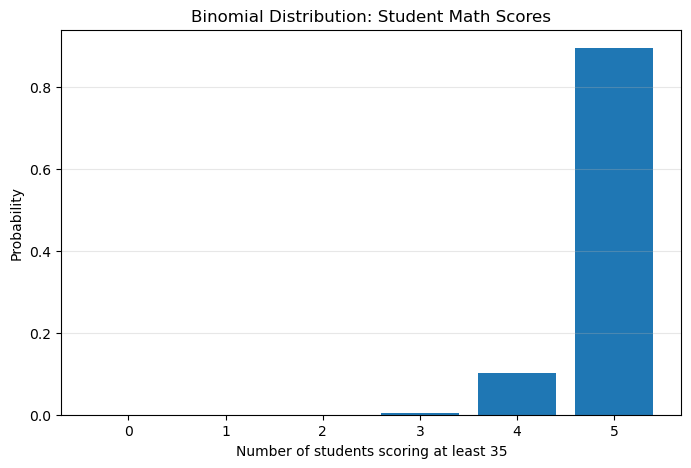

In [166]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.bar(success_counts, probabilities)

plt.title("Binomial Distribution: Student Math Scores")
plt.xlabel("Number of students scoring at least 35")
plt.ylabel("Probability")
plt.xticks(list(success_counts))
plt.grid(axis="y", alpha=0.3)

plt.show()

In [191]:
from scipy.stats import poisson

# Average number of calls per 10 minutes
lam = 3

# Number of calls we're interested in
k = 5

# Probability of exactly 5 calls
prob = poisson.pmf(k, lam)

print("Probability:", prob)
print("Percentage:", prob * 100)

Probability: 0.10081881344492458
Percentage: 10.081881344492457


In [194]:
k=[0,1,2]
lam = 3
prob = poisson.pmf(k,lam)
prob.sum()*100

np.float64(42.31900811268435)

In [195]:
1 - poisson.cdf(3, mu=3)

np.float64(0.35276811121776874)